<a href="https://colab.research.google.com/github/tutorbosun/Pipe-Flow-HeadLoss-Solver/blob/main/Pipe_Flow_Hydraulics_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Flow (m3/h)  | Re Number    | Hazen-Williams (m)   | Darcy-Weisbach (m)   | Error (%)
----------------------------------------------------------------------------------
18           | 6.34e+04     | 0.53                 | 0.45                 | 18.15%
36           | 1.27e+05     | 1.90                 | 1.62                 | 17.43%
54           | 1.90e+05     | 4.03                 | 3.49                 | 15.57%
72           | 2.54e+05     | 6.87                 | 6.04                 | 13.66%


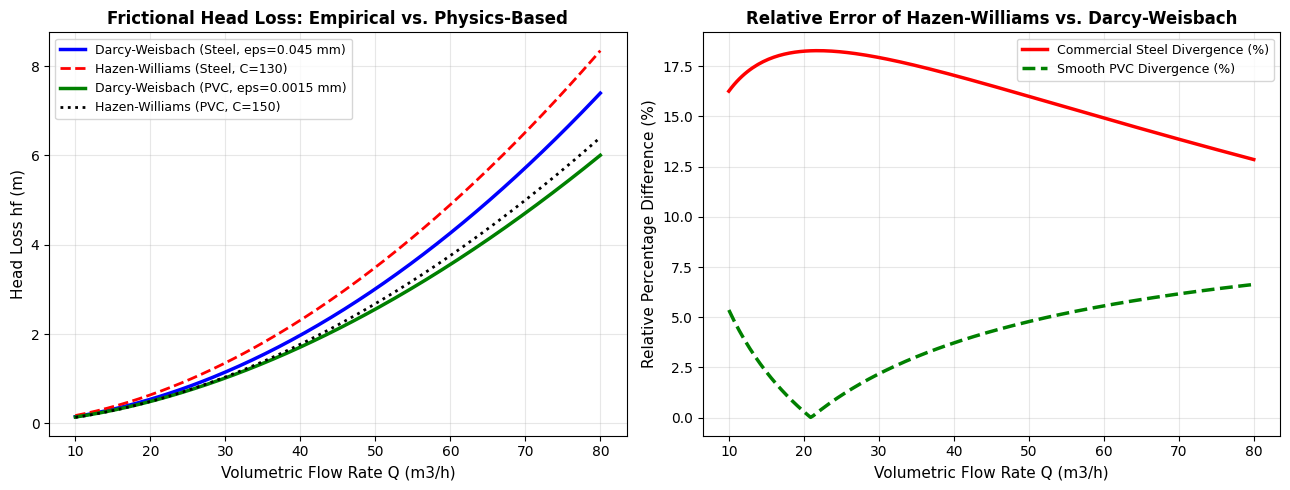

In [7]:
import numpy as np
import matplotlib.pyplot as plt


def hazen_williams_headloss(L, d, Q, C=130):
    """Empirical head loss for water at ~20°C (SI units)."""
    numerator = 10.67 * L * np.power(Q, 1.852)
    denominator = np.power(C, 1.852) * np.power(d, 4.87)
    return numerator / denominator


def darcy_weisbach_headloss(L, d, Q, eps=4.5e-5, nu=1.004e-6):
    """Physics-based head loss using the explicit Swamee-Jain friction factor."""
    g = 9.81
    area = np.pi * np.power(d / 2.0, 2)
    V = Q / area
    Re = (V * d) / nu

    # Swamee-Jain explicit approximation of the Colebrook-White equation
    term1 = eps / (3.7 * d)
    term2 = 5.74 / np.power(Re, 0.9)
    f = 0.25 / np.power(np.log10(term1 + term2), 2)

    return f * (L / d) * (np.power(V, 2) / (2.0 * g))


# 1. Print Exact Numerical Benchmark Table (18 to 72 m3/h)
L = 100.0  # Pipe length (m)
d = 0.1    # Pipe internal diameter (m)
flow_rates = np.linspace(18, 72, 4)  # Generates 18.0, 36.0, 54.0, 72.0

print(f"{'Flow (m3/h)':<12} | {'Re Number':<12} | {'Hazen-Williams (m)':<20} | {'Darcy-Weisbach (m)':<20} | {'Error (%)'}")
print("-" * 82)

for q_m3h in flow_rates:
    Q = q_m3h / 3600.0
    V = Q / (np.pi * np.power(d / 2.0, 2))
    Re = (V * d) / 1.004e-6

    hf_hw = hazen_williams_headloss(L, d, Q, C=130)
    hf_dw = darcy_weisbach_headloss(L, d, Q, eps=4.5e-5)
    err = np.abs(hf_hw - hf_dw) / hf_dw * 100.0

    print(f"{q_m3h:<12.0f} | {Re:<12.2e} | {hf_hw:<20.2f} | {hf_dw:<20.2f} | {err:.2f}%")

# 2. Generate Smooth Arrays for Plotting (10 to 80 m3/h)
q_array = np.linspace(10, 80, 200)
Q_array = q_array / 3600.0

# Commercial Steel Pipe (C = 130, eps = 0.045 mm)
hf_hw_steel = hazen_williams_headloss(L, d, Q_array, C=130)
hf_dw_steel = darcy_weisbach_headloss(L, d, Q_array, eps=4.5e-5)
err_steel = np.abs(hf_hw_steel - hf_dw_steel) / hf_dw_steel * 100.0

# Smooth PVC Pipe (C = 150, eps = 0.0015 mm)
hf_hw_pvc = hazen_williams_headloss(L, d, Q_array, C=150)
hf_dw_pvc = darcy_weisbach_headloss(L, d, Q_array, eps=1.5e-6)
err_pvc = np.abs(hf_hw_pvc - hf_dw_pvc) / hf_dw_pvc * 100.0

# 3. Create Publication-Quality Dual-Panel Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left Panel (ax1): Direct Head Loss Comparison
ax1.plot(q_array, hf_dw_steel, 'b-', linewidth=2.5, label='Darcy-Weisbach (Steel, eps=0.045 mm)')
ax1.plot(q_array, hf_hw_steel, 'r--', linewidth=2.0, label='Hazen-Williams (Steel, C=130)')
ax1.plot(q_array, hf_dw_pvc, 'g-', linewidth=2.5, label='Darcy-Weisbach (PVC, eps=0.0015 mm)')
ax1.plot(q_array, hf_hw_pvc, 'k:', linewidth=2.0, label='Hazen-Williams (PVC, C=150)')
ax1.set_title('Frictional Head Loss: Empirical vs. Physics-Based', fontsize=12, fontweight='bold')
ax1.set_xlabel('Volumetric Flow Rate Q (m3/h)', fontsize=11)
ax1.set_ylabel('Head Loss hf (m)', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# Right Panel (ax2): Relative Divergence Across Flow Regimes
ax2.plot(q_array, err_steel, 'r-', linewidth=2.5, label='Commercial Steel Divergence (%)')
ax2.plot(q_array, err_pvc, 'g--', linewidth=2.5, label='Smooth PVC Divergence (%)')
ax2.set_title('Relative Error of Hazen-Williams vs. Darcy-Weisbach', fontsize=12, fontweight='bold')
ax2.set_xlabel('Volumetric Flow Rate Q (m3/h)', fontsize=11)
ax2.set_ylabel('Relative Percentage Difference (%)', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('headloss_comparison_plot.png', dpi=300)
plt.show()
